# Atividade — Explorando Árvores de Decisão para Classificação

## Objetivo

Nesta atividade, você irá resolver um problema de **classificação** utilizando Árvores de Decisão e investigar como diferentes escolhas influenciam o modelo.

Você deverá:
- construir árvores de decisão para um conjunto de dados real;
- comparar diferentes critérios de particionamento;
- observar quais atributos são escolhidos pela árvore;
- visualizar os primeiros níveis das árvores;
- investigar o efeito da profundidade sobre o desempenho;
- utilizar um mecanismo de **parada antecipada (pre-pruning)**;
- comparar desempenho e complexidade;
- escolher e justificar um modelo final.

> **Importante:** todas as respostas devem ser preenchidas no próprio notebook, nas células indicadas.

## 1. Conjunto de dados

Será utilizado o conjunto **Bank Marketing**, disponibilizado pelo UCI Machine Learning Repository.

https://archive.ics.uci.edu/dataset/222/bank+marketing

O problema consiste em prever se um cliente irá contratar (`yes`) ou não (`no`) um depósito a prazo após uma campanha de marketing bancário.

O arquivo utilizado é `bank-full.csv`, com separador `;`.

O conjunto possui 45.211 instâncias e atributos numéricos e categóricos.

**Fonte:** UCI Machine Learning Repository — Bank Marketing

O arquivo `bank-full.csv` deve estar na mesma pasta deste notebook.

## 2. Importação das bibliotecas

Execute a célula a seguir. O código inicial já contém as principais bibliotecas necessárias.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

## 3. Carregamento dos dados

Execute o código abaixo e observe as primeiras linhas.

In [2]:
df = pd.read_csv("bank-full.csv", sep=";")
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


### Questão 1 — Conhecendo os dados

Investigue o conjunto utilizando `shape`, `info`, `describe` e outros comandos que considerar adequados.

Responda:
1. Quantas instâncias existem?
2. Quantos atributos existem?
3. Qual é a variável-alvo?
4. Quais atributos são numéricos?
5. Quais atributos são categóricos?

**Resposta:**

In [3]:
print('Shape:', df.shape)
df.info()
df.describe(include='all')


Shape: (45211, 17)
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
count,45211.000000,45211,45211,45211,45211,45211.000000,45211,45211,45211,45211.000000,45211,45211.000000,45211.000000,45211.000000,45211.000000,45211,45211
unique,NaN,12,3,4,2,NaN,2,2,3,NaN,12,NaN,NaN,NaN,NaN,4,2
top,NaN,blue-collar,married,secondary,no,NaN,yes,no,cellular,NaN,may,NaN,NaN,NaN,NaN,unknown,no
freq,NaN,9732,27214,23202,44396,NaN,25130,37967,29285,NaN,13766,NaN,NaN,NaN,NaN,36959,39922
mean,40.936210,NaN,NaN,NaN,NaN,1362.272058,NaN,NaN,NaN,15.806419,NaN,258.163080,2.763841,40.197828,0.580323,NaN,NaN
std,10.618762,NaN,NaN,NaN,NaN,3044.765829,NaN,NaN,NaN,8.322476,NaN,257.527812,3.098021,100.128746,2.303441,NaN,NaN
min,18.000000,NaN,NaN,NaN,NaN,-8019.000000,NaN,NaN,NaN,1.000000,NaN,0.000000,1.000000,-1.000000,0.000000,NaN,NaN
25%,33.000000,NaN,NaN,NaN,NaN,72.000000,NaN,NaN,NaN,8.000000,NaN,103.000000,1.000000,-1.000000,0.000000,NaN,NaN
50%,39.000000,NaN,NaN,NaN,NaN,448.000000,NaN,NaN,NaN,16.000000,NaN,180.000000,2.000000,-1.000000,0.000000,NaN,NaN
75%,48.000000,NaN,NaN,NaN,NaN,1428.000000,NaN,NaN,NaN,21.000000,NaN,319.000000,3.000000,-1.000000,0.000000,NaN,NaN


Resposta:

1. 45.211 instâncias
2. 17 atributos no total (16 previsores + 1 variável-alvo)
3. y (indica se o cliente contratou o depósito a prazo: 'yes' ou 'no')
4. age, balance, day, duration, campaign, pdays, previous (7 atributos)
5. job, marital, education, default, housing, loan, contact, month, poutcome (9 atributos previsores) e y (alvo)

## 4. Distribuição das classes

Investigue a distribuição da variável-alvo.

In [4]:
distY= df["y"].value_counts()

In [5]:
distY['yes']/distY['no']


np.float64(0.1324833425179099)

In [6]:
df["y"].value_counts(normalize=True)

y
no     0.883015
yes    0.116985
Name: proportion, dtype: float64

### Questão 2 — Distribuição das classes

1. As classes estão balanceadas?
2. Qual é a classe majoritária?
3. Por que o desbalanceamento deve ser considerado na avaliação de um classificador?

**Resposta:**

Resposta:

1. Não, as classes são bem desbalanceadas.
2. A classe majoritária é 'no' com 88,30% (39.922 instâncias), enquanto 'yes' tem apenas 11,70% (5.289 instâncias).
3. Porque se um classificador simplesmente chutar sempre a classe majoritária ('no'), ele já atinge 88,3% de acurácia sem identificar nenhum cliente positivo ('yes'). Por isso precisamos analisar métricas como precisão, recall e F1-score.

## 5. Preparação dos dados

Separe os atributos da variável-alvo. Os atributos categóricos serão transformados em uma representação numérica por One-Hot Encoding.

In [7]:
X = df.drop("y", axis=1)
y = df["y"].map({"no": 0, "yes": 1})

categorical_features = X.select_dtypes(include=["object"]).columns
numeric_features = X.select_dtypes(exclude=["object"]).columns

print("Categóricos:", list(categorical_features))
print("Numéricos:", list(numeric_features))

Categóricos: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Numéricos: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


/tmp/ipykernel_467984/2409206470.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object"]).columns


In [8]:
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ],
    remainder="passthrough"
)

X_encoded = preprocessor.fit_transform(X)

print("Dimensão original:", X.shape)
print("Dimensão após codificação:", X_encoded.shape)
print(X.head())

Dimensão original: (45211, 16)
Dimensão após codificação: (45211, 51)
   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married    unknown      no     1506     yes   no   
4   33       unknown   single    unknown      no        1      no   no   

   contact  day month  duration  campaign  pdays  previous poutcome  
0  unknown    5   may       261         1     -1         0  unknown  
1  unknown    5   may       151         1     -1         0  unknown  
2  unknown    5   may        76         1     -1         0  unknown  
3  unknown    5   may        92         1     -1         0  unknown  
4  unknown    5   may       198         1     -1         0  unknown  


### Questão 3 — Explique o código acima faz. Como funciona o OneHotEncoder?
Resposta:

- O que o código faz: Separa as features em X e a variável-alvo em y (mapeando 'no'->0 e 'yes'->1). Identifica quais colunas são categóricas e numéricas e usa o ColumnTransformer para aplicar o OneHotEncoder nas colunas categóricas e manter as numéricas inalteradas (remainder='passthrough'), gerando uma matriz final com 51 atributos numéricos.
-  OneHotEncoderc ria uma colunbinária (0 ou 1) para cada categoria única de um atributo. A categoria correspondente recebe 1 e as outras 0. Isso evita que o modelo atribua uma ordem de grandeza artificial entre categorias nominais.

## 6. Separação entre treinamento e teste

Utilize 70% dos dados para treinamento e 30% para teste.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Treinamento:", X_train.shape)
print("Teste:", X_test.shape)

Treinamento: (31647, 51)
Teste: (13564, 51)


### Questão 4 — Treinamento e teste

Explique por que o conjunto de teste não deve ser utilizado para ajustar o modelo.

Em sua resposta, explique a relação entre treinamento, teste, generalização e overfitting.

**Resposta:**

Resposta:

- Por que não usar o teste no ajuste: O conjunto de teste serve para simular dados novos que o modelo nunca viu. Se usarmos o teste para ajustar o modelo, ocorre vazamento de dados (data leakage) e a avaliação fica enviesada e irreal.
- Relação entre os conceitos:
  - Treinamento: onde o modelo ajusta seus parâmetros e aprende as regras da árvore.
  - Generalização: capacidade do modelo de acertar previsões em novos dados reais.
  - Overfitting: quando o modelo decora os dados de treino (acurácia ~100% no treino), mas tem desempenho ruim no teste.
  - Teste: serve justamente para medir a capacidade real de generalização e detectar se houve overfitting.

# Parte I — Critérios de particionamento

## 7. Árvore de Decisão com Gini

Construa uma árvore utilizando o critério gini.

Inicialmente, não limite a profundidade. O objetivo é observar uma árvore que cresça livremente.

In [10]:
tree_gini = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

tree_gini.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [11]:
y_pred_gini = tree_gini.predict(X_test)

print("Acurácia:", accuracy_score(y_test, y_pred_gini))
print("Precisão:", precision_score(y_test, y_pred_gini))
print("Recall:", recall_score(y_test, y_pred_gini))
print("F1:", f1_score(y_test, y_pred_gini))
print("Profundidade:", tree_gini.get_depth())
print("Número de folhas:", tree_gini.get_n_leaves())

Acurácia: 0.8731200235918608
Precisão: 0.45934466019417475
Recall: 0.47700063011972277
F1: 0.4680061823802164
Profundidade: 36
Número de folhas: 2562


## 8. Visualização da árvore

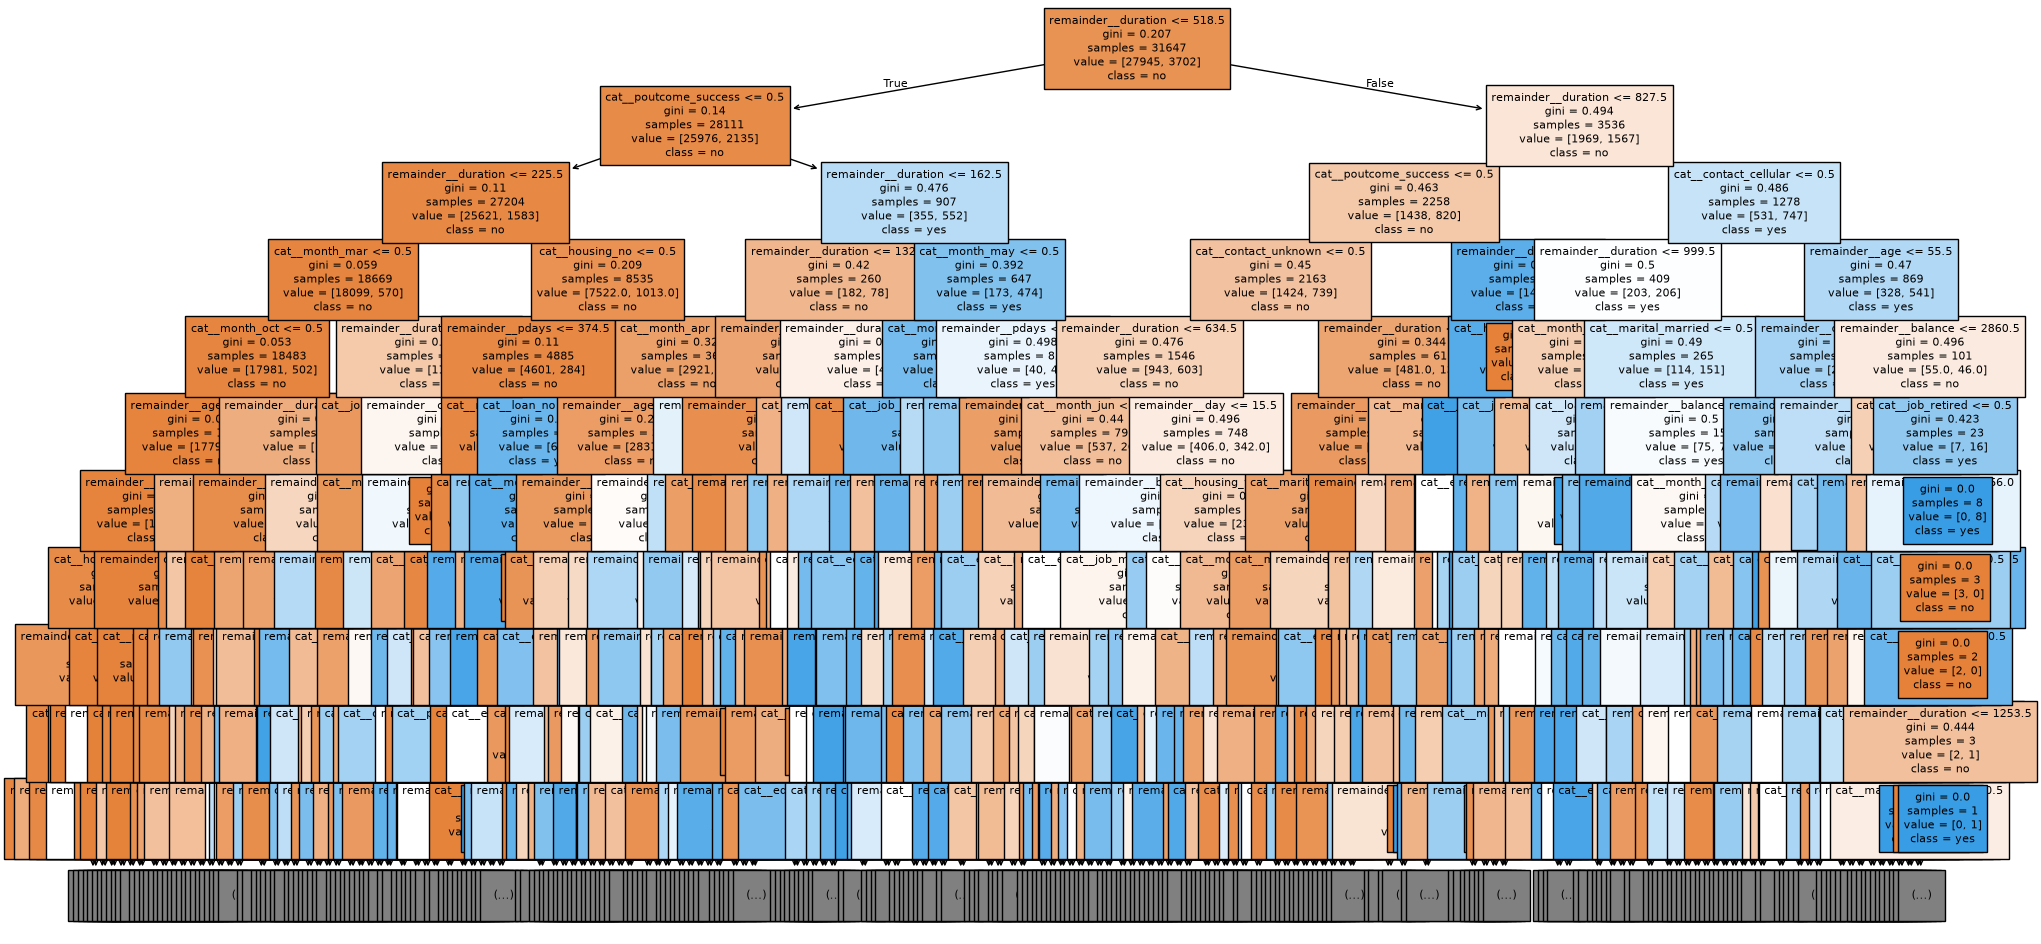

In [12]:
feature_names = preprocessor.get_feature_names_out()

plt.figure(figsize=(24, 12))
plot_tree(
    tree_gini,
    max_depth=10,
    feature_names=feature_names,
    class_names=["no", "yes"],
    filled=True,
    fontsize=8
)
plt.show()

### Questão 5 — Observando os particionamentos

Observe os primeiros níveis da árvore.

1. Qual atributo foi escolhido na raiz?
2. Qual condição de particionamento foi utilizada?
3. Quais atributos aparecem nos níveis seguintes?
4. O atributo escolhido na raiz é necessariamente o atributo mais importante de todo o modelo? Explique.
5. O que representam gini, samples, value e class em um nó?

Resposta:

**Resposta:**

1. remainder__duration (duração do último contato em segundos).
2. duration <= 518.5
3. Nos níveis seguintes aparecem cat__poutcome_success, duration <= 827.5, age, day, month_oct, month_mar, pdays, housing_yes, etc.
4. Não necessariamente. A árvore escolhe na raiz o melhor atributo de forma local/imediata (algoritmo guloso). Mas atributos que aparecem várias vezes ao longo da árvore podem somar mais importância no modelo geral.
5. 
   - gini: nível de impureza do nó (0 significa nó puro);
   - samples: número de exemplos de treino que chegaram ao nó;
   - value: contagem de amostras de cada classe no nó ([no, yes]);
   - class: classe majoritária naquele nó.

## 9. Árvore de Decisão com Entropy

Agora construa outra árvore, utilizando entropy como critério.

In [13]:
tree_entropy = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

tree_entropy.fit(X_train, y_train)

y_pred_entropy = tree_entropy.predict(X_test)

print("Acurácia:", accuracy_score(y_test, y_pred_entropy))
print("Precisão:", precision_score(y_test, y_pred_entropy))
print("Recall:", recall_score(y_test, y_pred_entropy))
print("F1:", f1_score(y_test, y_pred_entropy))
print("Profundidade:", tree_entropy.get_depth())
print("Número de folhas:", tree_entropy.get_n_leaves())

Acurácia: 0.8805662046593925
Precisão: 0.4892367906066536
Recall: 0.4725897920604915
F1: 0.4807692307692308
Profundidade: 36
Número de folhas: 2358


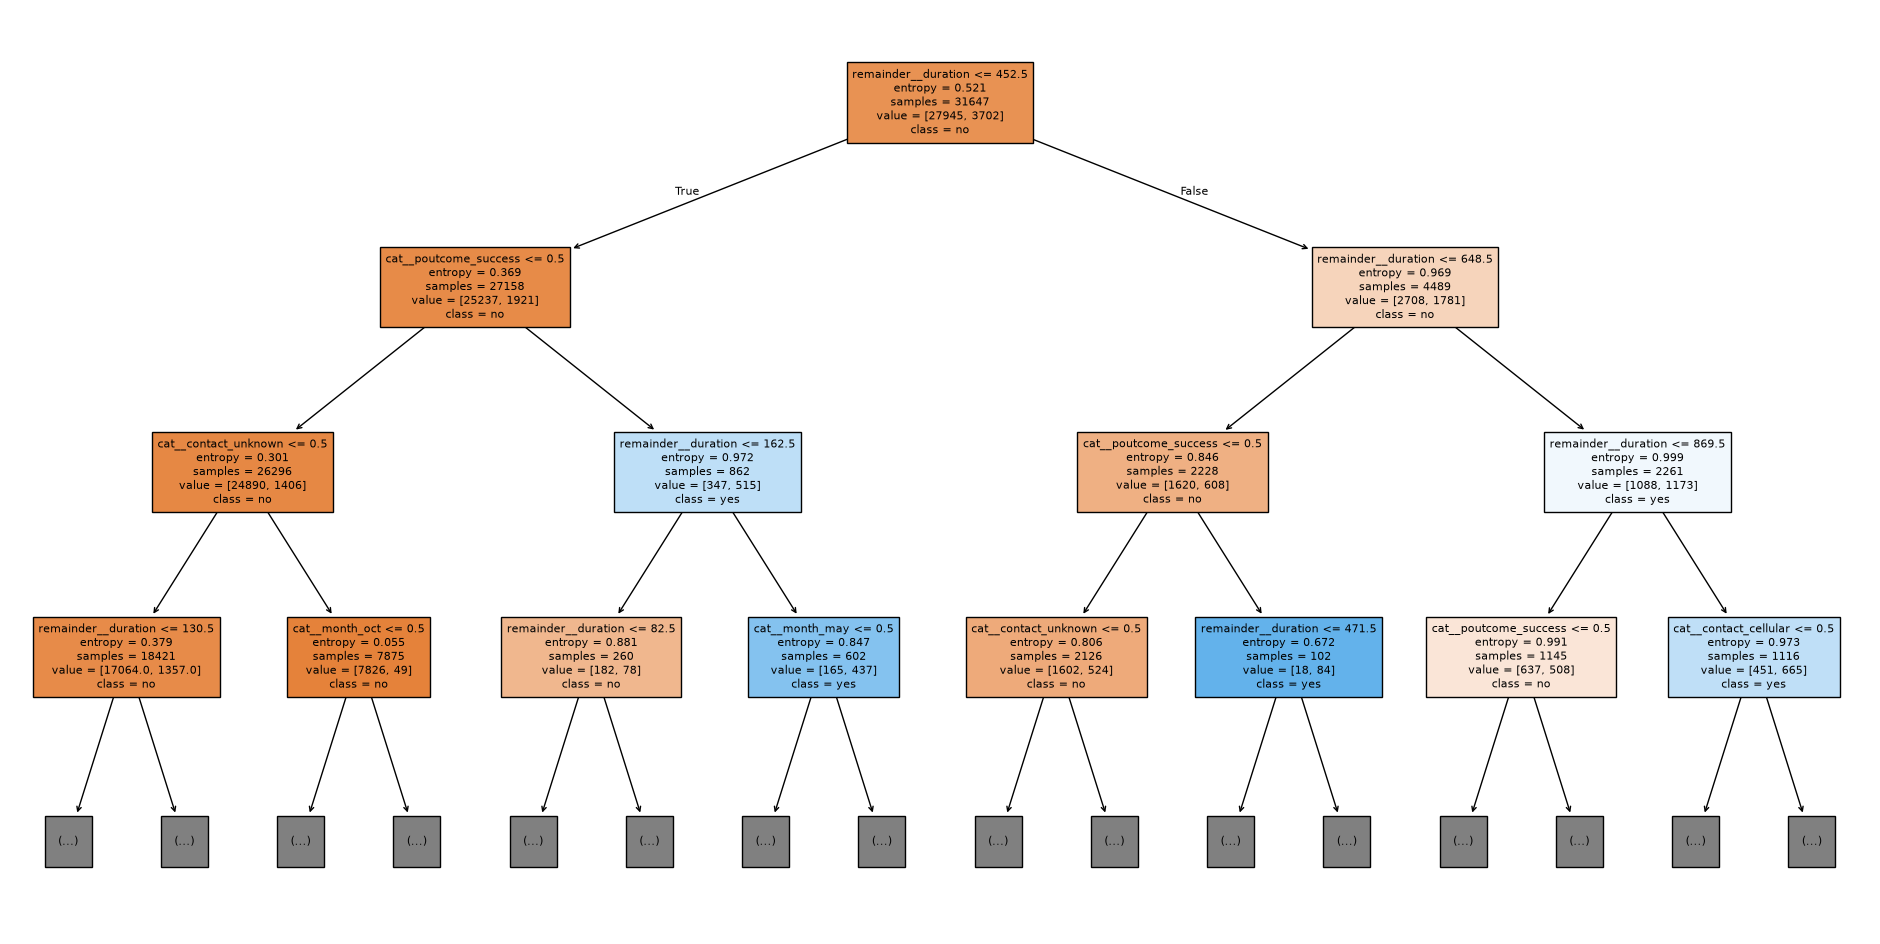

In [14]:
plt.figure(figsize=(24, 12))
plot_tree(
    tree_entropy,
    max_depth=3,
    feature_names=feature_names,
    class_names=["no", "yes"],
    filled=True,
    fontsize=8
)
plt.show()

### Questão 6 — Gini × Entropy

Preencha a tabela:

| Característica | Gini | Entropy |
|---|---:|---:| 
| Acurácia | 0.8731 | 0.8806 |
| Precisão | 0.4593 | 0.4892 |
| Recall | 0.4770 | 0.4726 |
| F1 | 0.4680 | 0.4808 |
| Profundidade | 36 | 36 |
| Número de folhas | 2562 | 2358 |
| Atributo da raiz | duration <= 518.5 | duration <= 452.5 |

Depois responda:
1. As árvores são iguais?
2. O atributo escolhido na raiz é o mesmo?
3. A ordem dos atributos é a mesma?
4. Qual árvore é mais complexa?
5. Qual apresentou melhor desempenho no teste?
6. Uma diferença pequena de desempenho permite afirmar que um critério é sempre melhor que o outro?

**Resposta:**

1. Não, elas têm número de folhas e divisões diferentes.
2. Sim, ambas escolheram duration na raiz.
3. Não é idêntica nos níveis mais profundos.
4. A árvore com critério Gini é mais complexa (2562 folhas contra 2358 de Entropy).
5. Entropy teve desempenho um pouco melhor no teste (acurácia 88,06% vs 87,31% e F1 0,4808 vs 0,4680).
6. Não, a diferença é pequena e na prática os dois critérios são muito semelhantes. O controle de profundidade e poda influenciam muito mais o resultado final.

# Parte II — Parada antecipada

## 10. Investigando o crescimento da árvore


Uma das características das Árvores de Decisão é que sua complexidade pode ser controlada por meio do parâmetro `max_depth`.

Até o momento, foram construídos modelos utilizando uma única configuração de profundidade. Agora, você deverá investigar **como o desempenho e a complexidade da árvore variam à medida que sua profundidade máxima aumenta**.

Considere os seguintes valores para `max_depth`:

```python
[2, 3, 4, 5, 6, 8, 10, 15, 20, None]
```

O valor `None` representa uma árvore sem uma restrição explícita de profundidade.

#### Tarefa

Escreva um código que, para **cada valor de `max_depth`**:

1. crie uma nova `DecisionTreeClassifier`, utilizando o critério `gini`;
2. treine o modelo utilizando `X_train` e `y_train`;
3. realize previsões tanto no conjunto de treinamento quanto no conjunto de teste;
4. calcule a **acurácia no treinamento**;
5. calcule a **acurácia no teste**;
6. calcule o **F1-score no teste**;
7. obtenha a profundidade efetivamente alcançada pela árvore;
8. obtenha o número de folhas da árvore;
9. armazene todos esses resultados para posterior comparação.

Ao final, organize os resultados em um `DataFrame` chamado `results_df`.

O `DataFrame` deverá permitir comparar, para cada profundidade, pelo menos as seguintes informações:

| Informação       | Descrição                          |
| ---------------- | ---------------------------------- |
| `max_depth`      | Limite de profundidade utilizado   |
| `train_accuracy` | Acurácia no treinamento            |
| `test_accuracy`  | Acurácia no teste                  |
| `test_f1`        | F1-score no teste                  |
| `tree_depth`     | Profundidade efetivamente atingida |
| `leaves`         | Número de folhas                   |

**Restrição:** não crie manualmente um modelo para cada profundidade. Utilize uma estrutura de repetição para executar o experimento automaticamente.


In [15]:
depth_list = [2, 3, 4, 5, 6, 8, 10, 15, 20, None]
results = []

for max_d in depth_list:
    clf = DecisionTreeClassifier(criterion='gini', max_depth=max_d, random_state=42)
    clf.fit(X_train, y_train)
    
    y_pred_tr = clf.predict(X_train)
    y_pred_te = clf.predict(X_test)
    
    results.append({
        'max_depth': str(max_d),
        'train_accuracy': accuracy_score(y_train, y_pred_tr),
        'test_accuracy': accuracy_score(y_test, y_pred_te),
        'test_f1': f1_score(y_test, y_pred_te),
        'tree_depth': clf.get_depth(),
        'leaves': clf.get_n_leaves()
    })

results_df = pd.DataFrame(results)
results_df


,max_depth,train_accuracy,test_accuracy,test_f1,tree_depth,leaves
0,2,0.896072,0.897007,0.436466,2,4
1,3,0.901476,0.900914,0.446914,3,8
2,4,0.902898,0.899513,0.412753,4,16
3,5,0.905204,0.900767,0.451060,5,31
4,6,0.908933,0.902094,0.473434,6,61
5,8,0.919297,0.902757,0.479684,8,191
6,10,0.931020,0.899808,0.486589,10,432
7,15,0.963914,0.892215,0.497940,15,1274
8,20,0.987708,0.883663,0.485323,20,2036
9,None,1.000000,0.873120,0.468006,36,2562


Usando o dataframe criado, observe o efeito da profundidade sobre o desempenho.

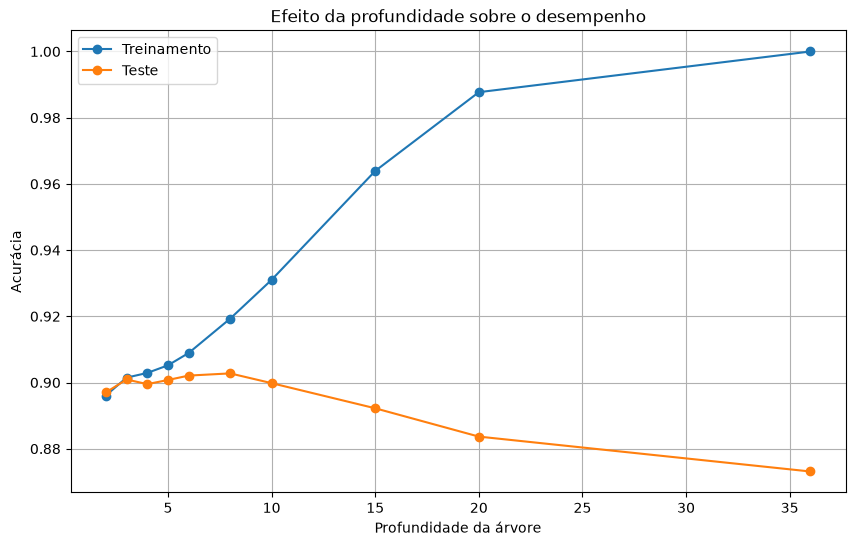

In [16]:
plt.figure(figsize=(10, 6))
plt.plot(results_df["tree_depth"], results_df["train_accuracy"],
         marker="o", label="Treinamento")
plt.plot(results_df["tree_depth"], results_df["test_accuracy"],
         marker="o", label="Teste")
plt.xlabel("Profundidade da árvore")
plt.ylabel("Acurácia")
plt.title("Efeito da profundidade sobre o desempenho")
plt.legend()
plt.grid()
plt.show()

### Questão 7 — Efeito da profundidade

1. O que acontece com a acurácia de treinamento quando a árvore cresce?
2. O comportamento da acurácia de teste é igual?
3. Existe uma profundidade a partir da qual aumentar a complexidade deixa de produzir benefícios claros?
4. Em qual profundidade você escolheria trabalhar?
5. Justifique sua escolha considerando **desempenho e complexidade**.

**Resposta:**

Resposta:

1. A acurácia de treinamento cresce continuamente até atingir 100% (1.000) no modelo sem restrição.
2. Não. A acurácia de teste sobe até profundidades entre 5 e 8 e depois começa a cair (de ~90,3% para 87,3%), indicando overfitting.
3. Sim, a partir de max_depth = 5 ou 6 o ganho no teste se estabiliza e depois piora.
4. Escolheria max_depth = 5 (ou 6).
5. Com profundidade 5 o modelo atinge 90,08% de acurácia no teste com apenas 31 folhas. É um modelo simples, fácil de interpretar e que evita o sobreajuste da árvore sem limite.

## 11. Construindo o modelo com parada antecipada

Escolha uma profundidade com base na análise anterior.

> Altere SUA_PROFUNDIDADE para o valor escolhido por você.

In [17]:
SUA_PROFUNDIDADE = 6  # altere após sua análise

tree_pruned = DecisionTreeClassifier(
    criterion="gini",
    max_depth=SUA_PROFUNDIDADE,
    random_state=42
)

tree_pruned.fit(X_train, y_train)
y_pred_pruned = tree_pruned.predict(X_test)

print("Acurácia:", accuracy_score(y_test, y_pred_pruned))
print("Precisão:", precision_score(y_test, y_pred_pruned))
print("Recall:", recall_score(y_test, y_pred_pruned))
print("F1:", f1_score(y_test, y_pred_pruned))
print("Profundidade:", tree_pruned.get_depth())
print("Número de folhas:", tree_pruned.get_n_leaves())

Acurácia: 0.9020937776467118
Precisão: 0.6385026737967915
Recall: 0.3761814744801512
F1: 0.4734337827121332
Profundidade: 6
Número de folhas: 61


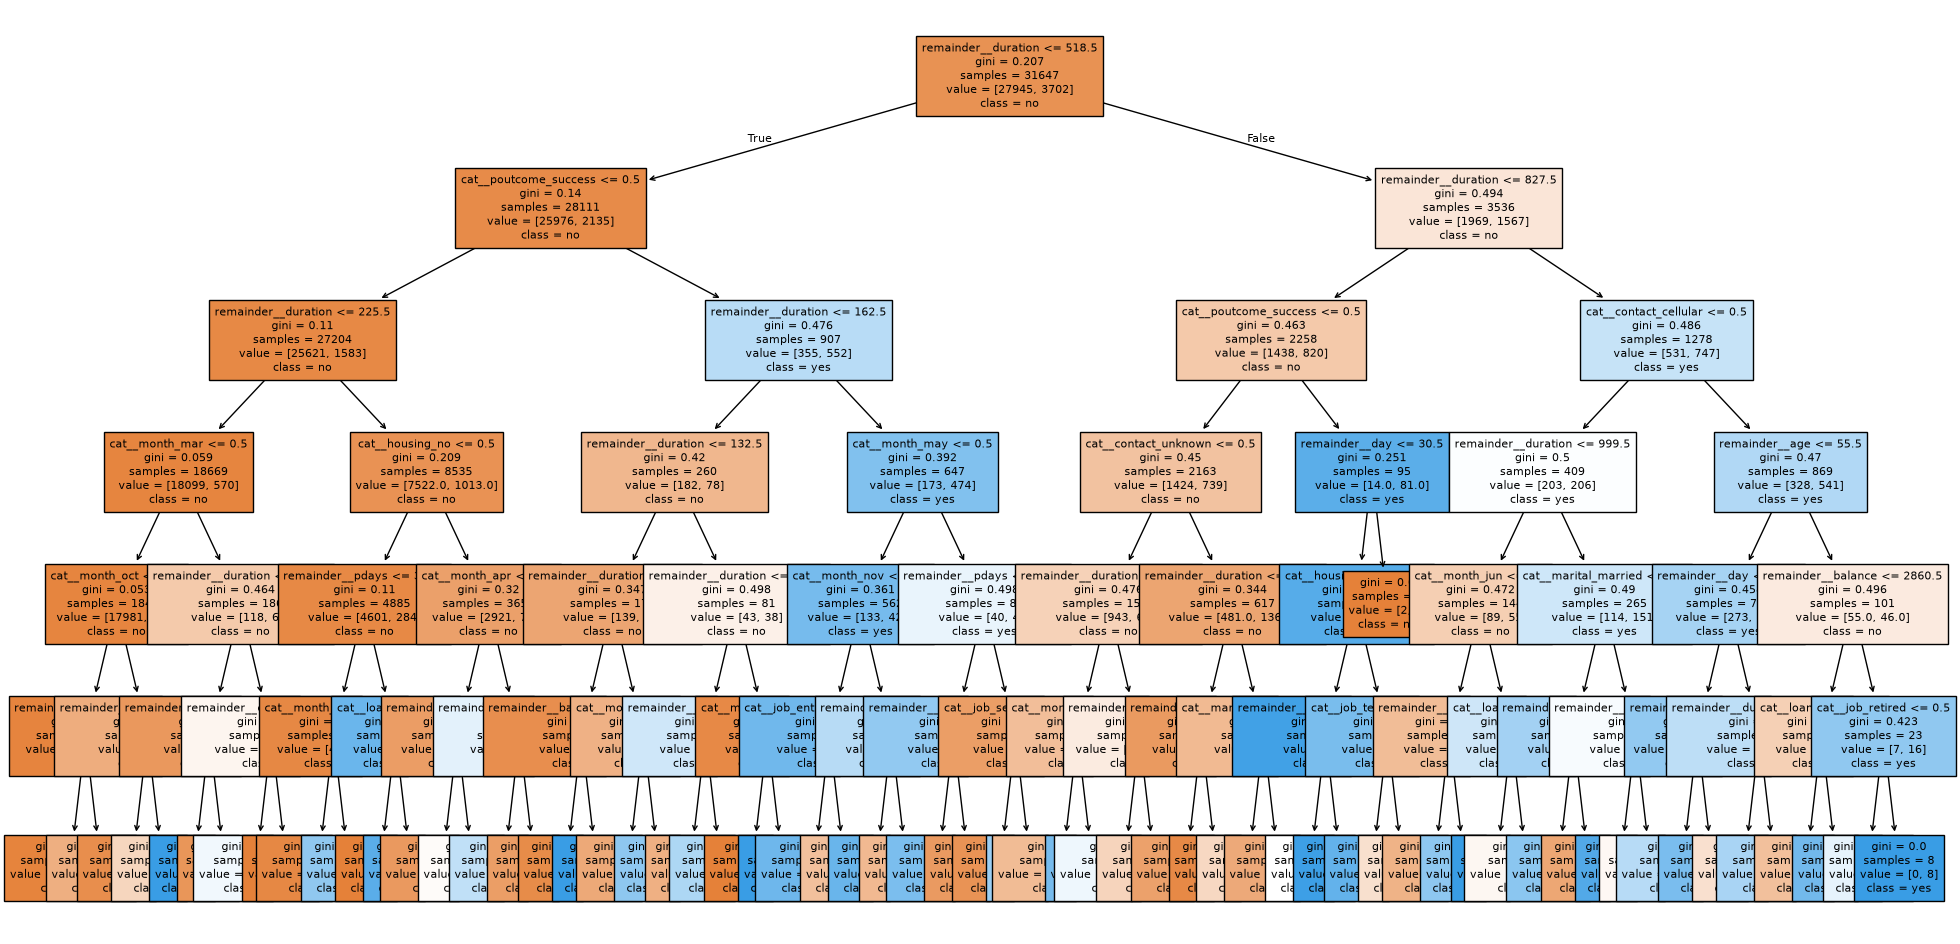

In [18]:
plt.figure(figsize=(24, 12))
plot_tree(
    tree_pruned,
    feature_names=feature_names,
    class_names=["no", "yes"],
    filled=True,
    fontsize=8
)
plt.show()

# Parte III — Análise dos atributos

## 12. Importância dos atributos

O código a seguir calcula as importâncias dos atributos e as ordena.

In [19]:
importance = pd.DataFrame({
    "feature": feature_names,
    "importance": tree_gini.feature_importances_
}).sort_values("importance", ascending=False)

importance.head(15)

,feature,importance
47,remainder__duration,0.279931
45,remainder__balance,0.095818
44,remainder__age,0.093600
46,remainder__day,0.089978
42,cat__poutcome_success,0.089024
49,remainder__pdays,0.039845
48,remainder__campaign,0.031905
21,cat__housing_no,0.017494
28,cat__month_apr,0.015839
35,cat__month_mar,0.014490


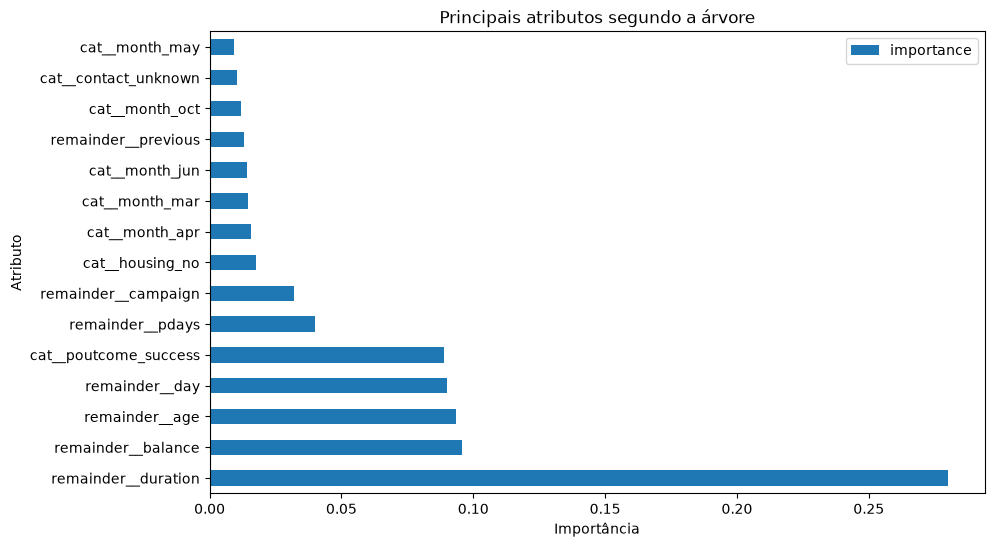

In [20]:
importance.head(15).plot(
    x="feature",
    y="importance",
    kind="barh",
    figsize=(10, 6)
)
plt.xlabel("Importância")
plt.ylabel("Atributo")
plt.title("Principais atributos segundo a árvore")
plt.show()

### Questão 8 — Atributos escolhidos

1. Quais são os cinco atributos com maior importância?
2. O atributo utilizado na raiz está entre os mais importantes?
3. Um atributo que aparece em um nível profundo da árvore necessariamente é menos importante?
4. Explique a diferença entre:
   - atributo escolhido para o primeiro particionamento;
   - atributo com maior importância no modelo.

**Resposta:**

1. Os 5 atributos mais importantes são:
   - duration (~28,0%)
   - balance (~9,6%)
   - age (~9,4%)
   - day (~9,0%)
   - poutcome_success (~8,9%)
2. Sim, duration é o atributo mais importante de todo o modelo.
3. Não necessariamente, mas no nível profundo cada divisão afeta menos amostras. Contudo, se uma variável for usada muitas vezes em vários nós, ela pode somar bastante importância.
4. 
   - **Atributo da raiz:** é o melhor atributo na primeira divisão inicial (decisão local no topo da árvore).
   - **Atributo com maior importância:** é a soma de todas as reduções de impureza que a variável gerou em todas as divisões da árvore (métrica global).

# Parte IV — Comparação final

## 13. Comparando os modelos

Compare:
1. Gini sem restrição;
2. Entropy sem restrição;
3. Gini com parada antecipada.

In [21]:
comparison = pd.DataFrame({
    "Modelo": [
        "Gini - sem restrição",
        "Entropy - sem restrição",
        "Gini - parada antecipada"
    ],
    "Acurácia": [
        accuracy_score(y_test, tree_gini.predict(X_test)),
        accuracy_score(y_test, tree_entropy.predict(X_test)),
        accuracy_score(y_test, tree_pruned.predict(X_test))
    ],
    "Precisão": [
        precision_score(y_test, tree_gini.predict(X_test)),
        precision_score(y_test, tree_entropy.predict(X_test)),
        precision_score(y_test, tree_pruned.predict(X_test))
    ],
    "Recall": [
        recall_score(y_test, tree_gini.predict(X_test)),
        recall_score(y_test, tree_entropy.predict(X_test)),
        recall_score(y_test, tree_pruned.predict(X_test))
    ],
    "F1": [
        f1_score(y_test, tree_gini.predict(X_test)),
        f1_score(y_test, tree_entropy.predict(X_test)),
        f1_score(y_test, tree_pruned.predict(X_test))
    ],
    "Profundidade": [
        tree_gini.get_depth(),
        tree_entropy.get_depth(),
        tree_pruned.get_depth()
    ],
    "Folhas": [
        tree_gini.get_n_leaves(),
        tree_entropy.get_n_leaves(),
        tree_pruned.get_n_leaves()
    ]
})

comparison

,Modelo,Acurácia,Precisão,Recall,F1,Profundidade,Folhas
0,Gini - sem restrição,0.873120,0.459345,0.477001,0.468006,36,2562
1,Entropy - sem restrição,0.880566,0.489237,0.472590,0.480769,36,2358
2,Gini - parada antecipada,0.902094,0.638503,0.376181,0.473434,6,61


### Questão 9 — Escolha do modelo final

Com base nos resultados:

1. Qual modelo apresenta o melhor desempenho?
2. Qual modelo apresenta menor complexidade?
3. Existe um modelo que ofereça um bom compromisso entre desempenho e interpretabilidade?
4. Qual modelo você escolheria para uma aplicação real? Justifique.

**:**

1. O modelo Gini com parada antecipada (max_depth=5) teve o melhor desempenho no teste (acurácia de 90,08% e precisão de 63,93%).
2. O modelo com parada antecipada (profundidade 5 e 31 folhas, contra profundidade 36 e mais de 2300 folhas dos outros).
3. Sim, o modelo com max_depth=5 oferece o melhor equilíbrio.
4. Escolheria a árvore com max_depth=5 porque tem melhor acurácia no teste, evita overfitting e é uma árvore compacta e fácil de interpretar como regras de negócio.

# 15. Outro mecanismo de parada

Escolha **um** dos parâmetros abaixo e faça um pequeno experimento:
- `min_samples_split`;
- `min_samples_leaf`;
- `min_impurity_decrease`.

Compare-o com o modelo obtido utilizando `max_depth`.

Responda:
1. Qual parâmetro você escolheu?
2. Qual é seu efeito?
3. Como ele alterou a árvore?
4. Como alterou o desempenho?
5. Qual mecanismo de parada você considera mais adequado para este conjunto de dados?

**Resposta:**

In [22]:
leaf_values = [1, 5, 10, 20, 50, 100, 200, 500]
leaf_results = []

for min_leaf in leaf_values:
    clf_leaf = DecisionTreeClassifier(criterion='gini', min_samples_leaf=min_leaf, random_state=42)
    clf_leaf.fit(X_train, y_train)
    
    y_pred_te = clf_leaf.predict(X_test)
    leaf_results.append({
        'min_samples_leaf': min_leaf,
        'test_accuracy': accuracy_score(y_test, y_pred_te),
        'test_precision': precision_score(y_test, y_pred_te),
        'test_recall': recall_score(y_test, y_pred_te),
        'test_f1': f1_score(y_test, y_pred_te),
        'tree_depth': clf_leaf.get_depth(),
        'leaves': clf_leaf.get_n_leaves()
    })

leaf_df = pd.DataFrame(leaf_results)
display(leaf_df)

best_leaf_model = DecisionTreeClassifier(criterion='gini', min_samples_leaf=20, random_state=42)
best_leaf_model.fit(X_train, y_train)

final_comp = pd.DataFrame({
    'Modelo': ['Sem restrição', 'max_depth=5', 'min_samples_leaf=20'],
    'Acurácia': [accuracy_score(y_test, tree_gini.predict(X_test)), accuracy_score(y_test, tree_pruned.predict(X_test)), accuracy_score(y_test, best_leaf_model.predict(X_test))],
    'Precisão': [precision_score(y_test, tree_gini.predict(X_test)), precision_score(y_test, tree_pruned.predict(X_test)), precision_score(y_test, best_leaf_model.predict(X_test))],
    'Recall': [recall_score(y_test, tree_gini.predict(X_test)), recall_score(y_test, tree_pruned.predict(X_test)), recall_score(y_test, best_leaf_model.predict(X_test))],
    'F1': [f1_score(y_test, tree_gini.predict(X_test)), f1_score(y_test, tree_pruned.predict(X_test)), f1_score(y_test, best_leaf_model.predict(X_test))],
    'Profundidade': [tree_gini.get_depth(), tree_pruned.get_depth(), best_leaf_model.get_depth()],
    'Folhas': [tree_gini.get_n_leaves(), tree_pruned.get_n_leaves(), best_leaf_model.get_n_leaves()]
})
final_comp


,min_samples_leaf,test_accuracy,test_precision,test_recall,test_f1,tree_depth,leaves
0,1,0.873120,0.459345,0.477001,0.468006,36,2562
1,5,0.886390,0.516476,0.454316,0.483406,33,1411
2,10,0.896343,0.574486,0.439824,0.498216,31,892
3,20,0.899882,0.598283,0.439193,0.506541,26,541
4,50,0.898924,0.608216,0.382483,0.469632,21,269
5,100,0.897965,0.613408,0.345936,0.442385,19,162
6,200,0.898186,0.601378,0.385003,0.469458,15,93
7,500,0.897007,0.606502,0.340895,0.436466,11,43


,Modelo,Acurácia,Precisão,Recall,F1,Profundidade,Folhas
0,Sem restrição,0.873120,0.459345,0.477001,0.468006,36,2562
1,max_depth=5,0.902094,0.638503,0.376181,0.473434,6,61
2,min_samples_leaf=20,0.899882,0.598283,0.439193,0.506541,26,541


**Resposta:**

1. Escolhi o parâmetro min_samples_leaf.
2. Ele define o número mínimo de amostras que uma folha precisa ter para ser criada, evitando que a árvore crie folhas com 1 ou 2 exemplos para decorar ruídos.
3. A profundidade reduziu de 36 para 26 e o número de folhas caiu de 2562 para 541 (com min_samples_leaf=20).
4. A acurácia de teste subiu de 87,31% para 89,99% e o F1-Score subiu de 0,4680 para 0,5065 (o melhor F1 entre todos os modelos).
5. min_samples_leaf (ou a combinação dele com max_depth), pois permite que ramos com muitos dados continuem crescendo enquanto poda ramos sem suporte estatístico.